[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/11-interpretation.ipynb)

# Interpretation and Fairness

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Explain why single coefficients of correlated inputs mislead, and use grouped permutation importance instead.</li>
<li>Give an exact local explanation of one prediction from a linear model.</li>
<li>Test whether a group variable drives a model's decisions.</li>
<li>Measure who receives the benefit of a model's decisions, and compare like with like before blaming a variable.</li>
</ul>
</div>

**Prerequisites:** <a href="../10-tuning/">Tuning and Experiment Tracking</a>. **Dataset:** Online Retail II. **Time:** about 45 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

The tuning page ended with a decision: the logistic regression is our final model. Before anyone relies on it, two questions need answers.

1. **What has it learned?** For debugging (is it using something it should not?), for trust (does the logic make sense to the people who will act on it?), and for insight.
2. **Whom does it serve, and whom does it leave out?** A model that ranks people or businesses decides who gets attention. That deserves a deliberate look, even with no demographic data in sight.

## What has it learned?

We start with the most direct reading: the logistic regression's coefficients. Because every input was put on a comparable scale inside the pipeline, their sizes can be compared.

In [2]:
from mlp_data import models
from IPython.display import display
from mlp_data.metrics import at_risk_report
from sklearn.metrics import roc_auc_score

cleaned = retail.clean_retail(load_retail())
sp = retail.build_splits(cleaned.sales, cleaned.returns, features="full")
train, valid = sp.train, sp.valid
F = models.FEATURES

champion = models.make_logistic().fit(train[F], train["y"])
challenger = models.make_boosting().fit(train[F], train["y"])
p = champion.predict_proba(valid[F])[:, 1]

names = champion[0].get_feature_names_out()                      # one readable name per model input
weights = pd.Series(champion[-1].coef_[0], index=names).sort_values(key=abs, ascending=False)
pd.DataFrame({"effect on the odds of returning": weights.head(12)}).rename_axis("input (standardised)")

,effect on the odds of returning
input (standardised),
tails__frequency,0.62
tails__monetary,0.45
tails__freq_90d,0.43
tails__freq_prev_90d,0.42
tails__freq_180d,-0.40
ratio__recency_over_gap,-0.34
tails__tenure_days,-0.18
tails__avg_gap_days,-0.14
tails__monetary_90d,-0.13


A positive weight pushes the probability of returning up; a negative one pushes it down. The strongest are frequency, spend and the recent order counts, as the exploration page predicted.

But look at three of them together:

| Input | Weight |
|---|---|
| orders in the last 90 days | positive |
| orders in the 90 days before that | positive |
| orders in the last 180 days | **negative** |

The last 180 days is simply the sum of the other two, so these three are almost the same information. The model splits credit among them in a way that is mathematically fine for prediction but **meaningless to read one by one**: nobody should conclude that ordering more over 180 days makes a customer *less* likely to return. This is the standard warning about **correlated inputs**: individual coefficients are unreliable when inputs move together.

<div class="admonition warning">
<p class="admonition-title">Do not read single coefficients of correlated features</p>
<p>Use them to see the rough picture, never to explain one input in isolation. For a trustworthy ranking of what matters, measure the damage when information is removed, <em>in groups</em>.</p>
</div>

## A more trustworthy view: grouped permutation importance

Shuffle a group of related inputs across customers (breaking their link to the outcome) and see how much the score falls. A big drop means the model leans on that information. We shuffle **groups** (all the window counts together, and so on) so correlated inputs cannot cover for one another. We do it for both models, as a cross-check.

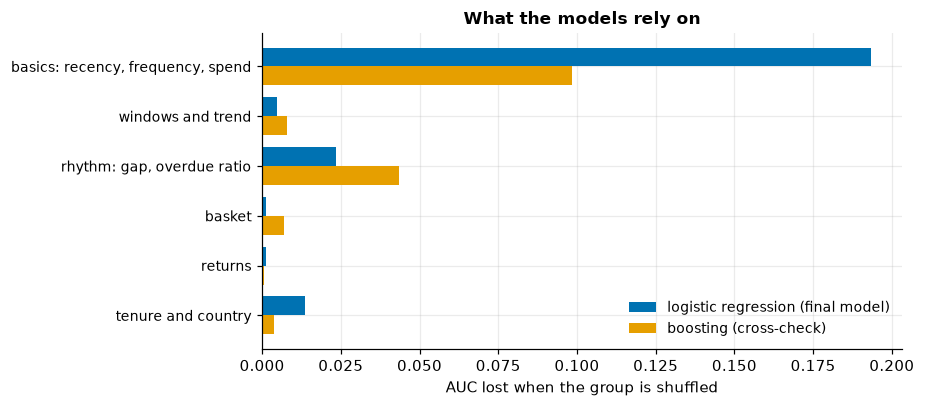

In [3]:
groups = {"basics: recency, frequency, spend": ["recency_days", "frequency", "monetary"],
          "windows and trend": ["freq_30d", "freq_90d", "freq_180d", "freq_prev_90d", "trend_90d", "monetary_90d"],
          "rhythm: gap, overdue ratio": ["avg_gap_days", "recency_over_gap"],
          "basket": ["avg_order_value", "items_per_order", "n_products"],
          "returns": ["n_returns", "return_value_share"],
          "tenure and country": ["tenure_days", "is_uk"]}
rng = np.random.default_rng(0)

def permutation_drop(model, cols, repeats=10):
    base = roc_auc_score(valid["y"], model.predict_proba(valid[F])[:, 1])
    drops = []
    for _ in range(repeats):
        shuffled = valid[F].copy()
        shuffled[cols] = shuffled[cols].to_numpy()[rng.permutation(len(shuffled))]      # shuffle the whole group together
        drops.append(base - roc_auc_score(valid["y"], model.predict_proba(shuffled)[:, 1]))
    return np.mean(drops)

importance = pd.DataFrame({name: {"logistic regression": permutation_drop(champion, cols), "boosting": permutation_drop(challenger, cols)} for name, cols in groups.items()}).T
fig, ax = plt.subplots(figsize=(8.5, 3.8))
y = np.arange(len(importance)); w = 0.38
ax.barh(y - w / 2, importance["logistic regression"], w, color=style.BLUE, label="logistic regression (final model)")
ax.barh(y + w / 2, importance["boosting"], w, color=style.ORANGE, label="boosting (cross-check)")
ax.set_yticks(y, importance.index, fontsize=9); ax.invert_yaxis(); ax.legend(loc="lower right")
ax.set(xlabel="AUC lost when the group is shuffled", title="What the models rely on")
plt.tight_layout(); plt.show()
assert importance.index[importance["logistic regression"].argmax()].startswith("basics") and importance.index[importance["boosting"].argmax()].startswith("basics")

**Reading the chart.** Both very different models say the same thing: **recency, frequency and spend carry the signal**, far ahead of anything else. The rhythm features (how overdue a customer is relative to their own pattern) come next. After that the two models disagree a little about the order of tenure and country versus the order-count windows, both small. Basket features and returns, which looked sensible, contribute almost nothing. This agrees with the feature page's finding that the extra groups added little, and it is reassuring that two unlike models point the same way.

## Why *this* customer? A local explanation

A manager looking at a single score will ask "why". For a logistic regression the answer is exact: the score is the intercept plus a sum of one contribution per input. Take the customer from the error analysis who ordered 94 times and then vanished, and who the model still rated as 91% likely to return.

customer 17850: predicted probability of returning = 90.8%   (log-odds +2.29 = intercept -0.74 + contributions +3.03)


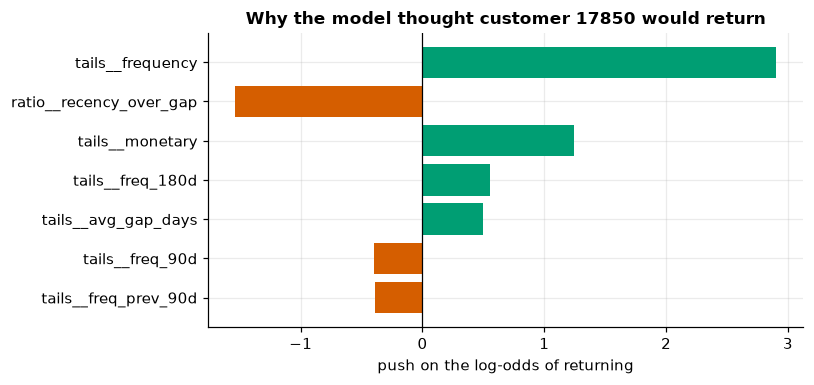

In [4]:
i = int(np.flatnonzero(valid["customer_id"].to_numpy() == 17850)[0])
x = champion[0].transform(valid[F].iloc[[i]])[0]                    # this customer's standardised inputs
contribution = pd.Series(x * champion[-1].coef_[0], index=names).sort_values(key=abs, ascending=False)
intercept = float(champion[-1].intercept_[0])
log_odds = intercept + contribution.sum()
print(f"customer 17850: predicted probability of returning = {p[i]:.1%}   (log-odds {log_odds:+.2f} = intercept {intercept:+.2f} + contributions {contribution.sum():+.2f})")
assert abs(1 / (1 + np.exp(-log_odds)) - p[i]) < 1e-9               # the explanation reproduces the score exactly
fig, ax = plt.subplots(figsize=(7.5, 3.6))
top = contribution.head(7)[::-1]
ax.barh(top.index, top.to_numpy(), color=[style.GREEN if v > 0 else style.RED for v in top])
ax.axvline(0, color="black", lw=0.8); ax.set(xlabel="push on the log-odds of returning", title="Why the model thought customer 17850 would return")
plt.tight_layout(); plt.show()

**Reading the chart.** The explanation adds up to the model's score exactly, which is the great virtue of a linear model: no approximation. The story is clear. An enormous order frequency pushes the prediction strongly towards "returns", the long silence relative to this customer's rhythm pushes back, and frequency wins. Seeing it laid out, we can see *why* the model is wrong here: it treats a hundred orders as overwhelming evidence of loyalty and has no way to say "someone who orders every two days and has been silent for six months has almost certainly gone".

## Does it treat groups consistently?

Our customers are mostly businesses, not people, and we hold no personal attributes. But **who the model sends a salesperson to** is still a decision with winners and losers, and a score can have uneven effects even when nobody intended it. A fairness review does not require protected characteristics. It requires asking, for the groups we *do* have, three things:

1. Is the model **equally accurate** for them? (We checked calibration by group on the evaluation page.)
2. Does the *input* matter? Does the model use a group variable, directly, to decide?
3. Who actually **receives the benefit**: the 200 calls?

Start with the second. We carry one variable that distinguishes groups, whether the customer is in the UK. Does it drive any decision?

In [5]:
as_uk = valid.assign(is_uk=1)                         # force every customer to be treated as UK
p_uk = champion.predict_proba(as_uk[F])[:, 1]
print(f"weight on 'is UK': {weights['rest__is_uk']:+.3f} (the largest weight is {weights.abs().max():.2f})")
print(f"largest change in anyone's probability if everyone were UK: {np.abs(p - p_uk).max():.3f}; average change: {np.abs(p - p_uk).mean():.4f}")
print(f"AUC with the real country {roc_auc_score(valid['y'], p):.4f}  vs  everyone treated as UK {roc_auc_score(valid['y'], p_uk):.4f}")

weight on 'is UK': -0.079 (the largest weight is 0.62)
largest change in anyone's probability if everyone were UK: 0.073; average change: 0.0043
AUC with the real country 0.7960  vs  everyone treated as UK 0.7959


Country has a **negligible** influence on any customer's score: the weight is tiny and forcing everyone to "UK" changes the AUC in the fourth decimal. So the model is not using country to discriminate. It adds essentially nothing, which means we could remove it with no loss and one less thing to defend; we record that as a recommendation for the next model version rather than editing a validated model in passing.

Now the third question, the important one: **who gets the calls?** For each grouping we compare the group's share of all customers, its share of the customers who really lapsed, its share of the 200 calls, and what fraction of its lapsers the calls actually reach.

In [6]:
v = valid.assign(p=p, lapse=1 - valid["y"], value_at_risk=(1 - p) * valid["monetary"])
calls = v.nlargest(200, "value_at_risk")

def coverage(label, groups):
    tab = pd.DataFrame({
        "share of customers": groups.value_counts(normalize=True),
        "share of lapsers": groups[v["lapse"] == 1].value_counts(normalize=True),
        "share of the 200 calls": groups.loc[calls.index].value_counts(normalize=True),
    }).fillna(0)
    tab["lapsers reached"] = [calls.loc[groups.loc[calls.index] == g, "lapse"].sum() / v.loc[groups == g, "lapse"].sum() for g in tab.index]
    tab.index = [f"{label}: {g}" for g in tab.index]
    return tab

report = pd.concat([
    coverage("spend", pd.qcut(v["monetary"], 4, labels=["lowest quarter", "2nd", "3rd", "highest quarter"])),
    coverage("country", v["is_uk"].map({1: "UK", 0: "outside UK"})),
    coverage("tenure", pd.cut(v["tenure_days"], [0, 90, 366, 10_000], right=False, labels=["under 90 days", "90 to 365 days", "over a year"])),
])
report.map("{:.1%}".format)

,share of customers,share of lapsers,share of the 200 calls,lapsers reached
spend: lowest quarter,25.0%,34.0%,0.0%,0.0%
spend: 2nd,25.0%,29.5%,0.0%,0.0%
spend: 3rd,25.0%,24.8%,0.0%,0.0%
spend: highest quarter,25.0%,11.8%,100.0%,26.4%
country: UK,91.5%,92.3%,80.0%,2.5%
country: outside UK,8.5%,7.7%,20.0%,10.0%
tenure: under 90 days,8.8%,8.3%,0.5%,0.4%
tenure: 90 to 365 days,42.6%,50.9%,26.5%,2.3%
tenure: over a year,48.6%,40.8%,73.0%,4.7%


**Reading the table.** Three things, in order of importance.

1. **Spend decides everything.** All 200 calls go to the highest quarter of customers by spend. The other three quarters hold roughly **88% of all the lapsers** and receive **none** of the calls. This is not a bug: we deliberately ranked by *value at risk*, which is the right way to protect revenue within a budget. But it means the system, as designed, automates neglect of small customers. Whether that is acceptable is a **business and policy decision**, and the business must see this table to make it.

2. **Country shows a disparity.** Customers outside the UK are under a tenth of customers yet a fifth of the calls. The previous check showed the model does not use country, so it is not favouring a location. But "the model ignores country" and "outcomes are even across countries" are different claims, and we should find out what is really happening.
3. **New customers are nearly invisible.** Those under 90 days old are about 9% of customers and get almost no calls (they are small, and the model also under-predicts their return rate, as we found).

<div class="admonition tip">
<p class="admonition-title">Fairness is a design choice with options, not a number to minimise</p>
<ul>
<li><strong>Accept and complement:</strong> keep the value-ranked calls for large accounts and run a cheap, automated campaign (an email, say) for the long tail, so no group is simply ignored.</li>
<li><strong>Allocate by segment:</strong> give each spend tier its own call quota, ranking within the tier.</li>
<li><strong>Monitor:</strong> track these coverage numbers over time so a drift in who gets served is noticed.</li>
</ul>
<p>The model cannot choose between these. People can, once it shows them the trade-off.</p>
</div>

### Digging into the country gap

A natural guess is that overseas customers simply spend more, so the gap is about spend, not country. Test the guess by comparing like with like: only the highest-spend quarter of customers, then even finer bands of spend.

In [7]:
top_quarter = v[v["monetary"] >= v["monetary"].quantile(0.75)].assign(country=lambda d: d["is_uk"].map({1: "UK", 0: "outside UK"}), called=lambda d: d.index.isin(calls.index))
profile = top_quarter.groupby("country").agg(customers=("called", "size"), called=("called", "sum"), share_called=("called", "mean"),
                                             median_spend=("monetary", "median"), median_orders=("frequency", "median"),
                                             median_days_silent=("recency_days", "median"), median_order_value=("avg_order_value", "median"))
print("Top-spend quarter only:")
display(profile.assign(share_called=profile["share_called"].map("{:.1%}".format)).round(0))

v["spend_decile"] = pd.qcut(v["monetary"], 10, labels=range(1, 11))
bands = v[v["spend_decile"].isin([8, 9, 10])].assign(called=lambda d: d.index.isin(calls.index))
finer = bands.groupby(["spend_decile", "is_uk"], observed=True)["called"].agg(["size", "mean"]).unstack()
finer.columns = [f"{'UK' if uk else 'outside UK'} {what}" for what, uk in finer.columns]
print("Share called, by spend tenth (8 = lower of the top three tenths):")
finer[["UK size", "UK mean", "outside UK size", "outside UK mean"]].rename(columns={"UK mean": "UK share called", "outside UK mean": "outside UK share called"}).round(3)

Top-spend quarter only:


,customers,called,share_called,median_spend,median_orders,median_days_silent,median_order_value
country,,,,,,,
UK,958,160,16.7%,"2,843.00",7.00,27.00,417.00
outside UK,123,40,32.5%,"3,338.00",5.00,51.00,798.00


Share called, by spend tenth (8 = lower of the top three tenths):


,UK size,UK share called,outside UK size,outside UK share called
spend_decile,,,,
8,391,0.00,41,0.00
9,386,0.12,46,0.24
10,375,0.30,58,0.50


**Reading it.** The guess is **wrong, or at least incomplete**. Even inside the top-spend quarter, overseas customers are called about twice as often as UK customers, and the gap persists within finer spend bands (overseas bands are small, so individual cells are noisy, but the direction is consistent).

The profiles show why. High-spend overseas customers place **much larger orders** (a median order value roughly double), **order less often**, and have been **silent longer**. To the model, those are textbook signs of a large account that may be drifting away, so their value at risk is higher. The model is reacting to **behaviour**, not to the country label, but because behaviour differs by country, the effect still lands unevenly by country. This is how a variable you remove can still leave its footprint: through the correlated things that remain.

Is that a problem? Maybe not: if overseas wholesalers with big baskets really are the accounts most worth a call, concentrating calls on them is the *intended* result. But it should be a conscious choice, made by someone who has seen this table, and tracked over time.

## Check yourself

<details class="question">
<summary>1. Why did the weight on 'orders in the last 180 days' come out negative?</summary>

Because it is almost exactly the sum of the 90-day and previous-90-day counts, which carry positive weights. With nearly duplicate inputs the model can trade weight between them freely without changing its predictions, so the individual signs and sizes are unstable and carry no standalone meaning. That is why we read *groups* of related inputs (permutation importance) instead.

</details>

<details class="question">
<summary>2. The model never sees a customer's name or any personal attribute, and country has almost no weight. Does that make it fair?</summary>

Not automatically. Fairness is about *outcomes*, not just inputs. Here, the decision to rank by value means three quarters of customers (and most lapsers) receive no attention at all. A model can be neutral about a variable and still produce an uneven result through correlated quantities like spend. You have to measure who receives the benefit.

</details>

<details class="question">
<summary>3. Overseas customers get a fifth of the calls despite being under a tenth of customers. Is that evidence the model discriminates by country?</summary>

Not by country as an input: the model gives the country flag almost no weight, and forcing everyone to 'UK' barely changes any score. But the disparity is real and does not vanish when comparing customers of similar spend. It comes from *behaviour* that differs by country (bigger orders, less frequent, longer silence), which the model reads as high value at risk. So removing a variable does not remove its footprint: correlated behaviour carries it. Whether that outcome is acceptable is a policy decision; the lever for changing it is the allocation rule, not the scoring model.

</details>

## Exercise

<details class="question">
<summary>What would the group coverage look like if we ranked by the plain probability of lapsing instead of value at risk? Predict who would be called, then check.</summary>

```python
by_probability = v.assign(lapse_probability=1 - v["p"]).nlargest(200, "lapse_probability")
spend_group = pd.qcut(v["monetary"], 4, labels=["lowest quarter", "2nd", "3rd", "highest quarter"])
print(spend_group.loc[by_probability.index].value_counts(normalize=True).round(3).to_dict())
print("past-year spend of those 200 (median):", by_probability["monetary"].median().round(0))
```

The calls would flip toward the opposite end: the customers most certain to lapse are overwhelmingly small, one-off buyers, so roughly nine in ten of the 200 would come from the lowest spend quarter, with a median past-year spend of about £90 against about £4,900 for the value-ranked list. Coverage across spend groups would look *fairer* (small customers finally get attention), but the revenue protected would collapse, as the baselines page showed. This is the trade-off in miniature: a different ranking rule moves benefit between groups and the money with it, and choosing between them is a decision about priorities.

</details>

## Recap

- Read a model at three levels: **global** (what it relies on), **local** (why this score), and **by group** (who it serves).
- **Individual coefficients of correlated inputs are unreliable.** Use grouped permutation importance, and cross-check with a very different model.
- A linear model gives **exact local explanations**: the score is the sum of the contributions, and it can show why a mistake happened.
- A fairness review does not need protected attributes. Check whether a group variable drives the score, whether accuracy is equal, and, most importantly, **who receives the benefit**.
- **Removing or ignoring a variable does not remove its footprint.** The model gave country almost no weight, yet outcomes still differed by country through correlated behaviour. Check outcomes, not just inputs, and compare like with like before explaining a disparity away.
- Disparities in who is served are usually **design and policy choices**: surface them to the people who can decide.

**Next:** *Packaging and serving*, turning the validated model into something other systems can call safely.